# OCR, Image Captioning, and Image Retrieval

**Notebook 3.** Three tasks where computer vision meets language. Each task has a visual or live demo,
a step-by-step explanation of the architecture, and an evaluation with metrics that can be read without a technical background.

| Task | Input | Output | Demo |
|---|---|---|---|
| **OCR** (Optical Character Recognition) | A picture that contains text | The text, as characters | **Live on the webcam** |
| **Image captioning** | A picture | One sentence describing it | A **CNN + LSTM** model trained from scratch, shown word by word |
| **Image retrieval** | A text or a picture | The most similar pictures of a collection | Search with **CLIP** |

**The common idea.** In all three tasks, a picture is converted into numbers, and the numbers are converted into something useful for a human:
letters (OCR), words (captioning), or a ranked list of pictures (retrieval).

| Task | Main metrics | Plain meaning |
|---|---|---|
| OCR | **CER**, **WER** | What share of the characters or words is wrong? |
| Captioning | **BLEU**, attribute accuracy | How close is the sentence to what a human would write? |
| Retrieval | **Precision@K**, **Recall@K**, **mAP** | Are the right pictures at the top of the list? |

## Step 0: Setup (one time)

Terminal commands, in the folder of this notebook:

```bash
# 1. Create and activate a virtual environment
python -m venv .venv
source .venv/bin/activate            # Windows PowerShell: .venv\Scripts\Activate.ps1

# 2. Install PyTorch
pip install torch torchvision        # CPU only (smaller): add  --index-url https://download.pytorch.org/whl/cpu

# 3. Install the other tools
pip install ipykernel transformers pillow matplotlib numpy opencv-python rapidocr-onnxruntime nltk
```

Then in VS Code: **Select Kernel** > **Python Environments** > **.venv**.

**Camera permission** (Part 1 only): Windows: Settings > Privacy & security > Camera. macOS: System Settings > Privacy & Security > Camera > enable Visual Studio Code, then restart it.

**Downloads and hardware**

| Item | Size | Used in |
|---|---|---|
| OCR models | Inside the `rapidocr-onnxruntime` package (works offline) | Part 1 |
| CIFAR-10 pictures | about 170 MB | Part 3 |
| CLIP model | about 0.6 GB (shared with Notebook 2) | Part 3 |
| BLIP model (optional) | about 1 GB | Part 2 bonus |

Everything runs on a CPU: OCR needs roughly 0.2 to 0.6 s per frame, training the captioning model takes 1 to 3 minutes,
and embedding 1,000 pictures with CLIP takes about 1 minute.

In [ ]:
%pip install -q torch torchvision transformers pillow matplotlib numpy opencv-python rapidocr-onnxruntime nltk

## Step 1: Imports

- `cv2` (OpenCV): camera and drawing on images
- `PIL`: creating and editing pictures
- `torch`: neural networks (used by the captioning model and by CLIP)
- `matplotlib`: every figure of this notebook

In [1]:
import time
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from PIL import Image, ImageDraw, ImageFilter, ImageFont
from IPython.display import display, clear_output, Image as NotebookImage

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)
print("Tools loaded. PyTorch", torch.__version__)

Tools loaded. PyTorch 2.15.0+cu132


# Part 1: OCR (reading text from pictures)

**OCR** converts the pixels of a picture into characters that a computer can search, copy, or translate.
Typical uses: scanning documents, reading license plates, translating a sign with a phone camera, extracting data from receipts.

## The pipeline

| Step | Name | What happens | Analogy |
|---|---|---|---|
| 1 | **Detection** | A network finds **where** the text is and draws a box around each line | Spotting the paragraphs on a page |
| 2 | **Direction check** | Upside-down or tilted lines are straightened | Turning the page the right way |
| 3 | **Recognition** | Each box is cropped and **read** character by character | Zooming on one line and reading letter by letter |
| 4 | **Output** | The text and a **confidence** (sureness) for each line | The transcript |

## How recognition works: CNN + LSTM + CTC

The cropped line is a thin strip. It is cut into many narrow vertical **slices**, then:

1. A **CNN** extracts the visual features of every slice (curves, lines, corners).
2. An **LSTM** reads the slices from left to right, so every guess can use the context of its neighbors.
3. For every slice, the model predicts one **letter or a blank** (written `-`).
4. **CTC** (Connectionist Temporal Classification) merges repeated letters and removes the blanks.

The blank is what allows double letters: in "hello", the two l's must be separated by a blank, otherwise they would be merged into one.
The next cell shows this merging rule.

The CNN + LSTM combination is also the architecture of the captioning model in Part 2.
The difference: OCR produces one letter per slice of the picture, while captioning writes words freely.

In [2]:
def ctc_collapse(slices, blank="-"):
    """CTC rule: merge repeated symbols, then remove blanks."""
    text, previous = "", None
    for symbol in slices:
        if symbol != previous and symbol != blank:
            text += symbol
        previous = symbol
    return text


# What the network predicts for 13 slices of a strip that shows the word "hello"
slices = ["h", "h", "-", "e", "e", "-", "l", "l", "-", "l", "-", "o", "o"]

print("Slice number :", " ".join(f"{i + 1:>2}" for i in range(len(slices))))
print("Prediction   :", " ".join(f"{s:>2}" for s in slices))
print("After CTC    :", ctc_collapse(slices))

Slice number :  1  2  3  4  5  6  7  8  9 10 11 12 13
Prediction   :  h  h  -  e  e  -  l  l  -  l  -  o  o
After CTC    : hello


## Step 2: Settings and loading the OCR engine

| Setting | Meaning |
|---|---|
| `OCR_ENGINE` | `"rapidocr"` is fast and recommended (models included in the package). `"easyocr"` is an alternative (`pip install easyocr`, downloads models on first use) |
| `OCR_WIDTH` | Camera frames are shrunk to this width before reading, which makes OCR faster |
| `OCR_EVERY_N_FRAMES` | The AI reads one frame out of N. The boxes stay on screen in between, so the video stays smooth |
| `MIN_CONFIDENCE` | Lines with a lower sureness are ignored |
| `EXPECTED_TEXT` | Optional. The text that is really written in front of the camera, used to compute a live error rate |
| `DISPLAY_MODE` | `"window"` (fast, **Q** to stop) or `"notebook"` |

The camera image is **not mirrored** in this part, because mirrored text would be unreadable.

In [3]:
OCR_ENGINE         = "rapidocr"   # "rapidocr" or "easyocr"
OCR_WIDTH          = 640
OCR_EVERY_N_FRAMES = 3
MIN_CONFIDENCE     = 0.5
EXPECTED_TEXT      = ""           # example: "Hello World" (leave empty for no live error rate)
CAMERA_INDEX       = 0
DISPLAY_MODE       = "window"
MAX_SECONDS        = None


class OCR:
    """Small wrapper: both engines return a list of (box, text, confidence)."""

    def __init__(self, engine_name):
        self.name = engine_name
        if engine_name == "rapidocr":
            from rapidocr_onnxruntime import RapidOCR
            self.engine = RapidOCR()
        else:
            import easyocr
            self.engine = easyocr.Reader(["en"], gpu=False)

    def read(self, image_bgr):
        lines = []
        if self.name == "rapidocr":
            result, _ = self.engine(image_bgr)               # result is None when no text is found
            for box, text, score in (result or []):
                lines.append((np.array(box, dtype=np.float32), text, float(score)))
        else:
            for box, text, score in self.engine.readtext(image_bgr):
                lines.append((np.array(box, dtype=np.float32), text, float(score)))
        return lines


ocr = OCR(OCR_ENGINE)
print("OCR engine ready:", OCR_ENGINE)

OCR engine ready: rapidocr


## Step 3: The pipeline on a sample sign

A sign with three lines of text is drawn by the notebook itself, so that the **true text is known**.
The cell shows the stages one by one:

1. **Input**: the picture
2. **Detection**: the boxes found by the first network
3. **Recognition**: every box is cropped and read, with the sureness of the model

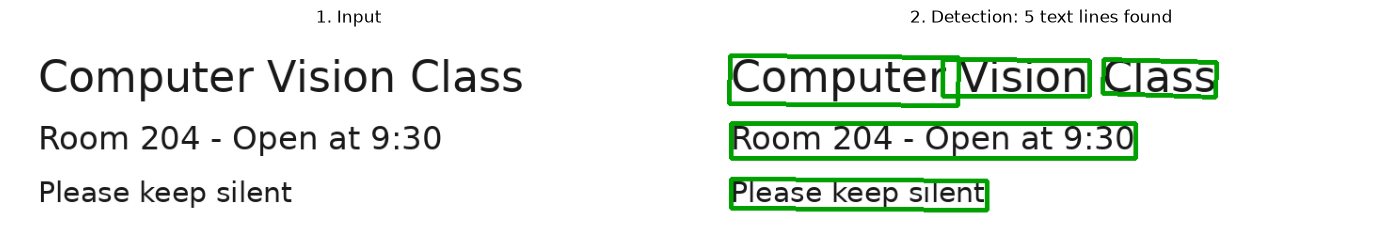

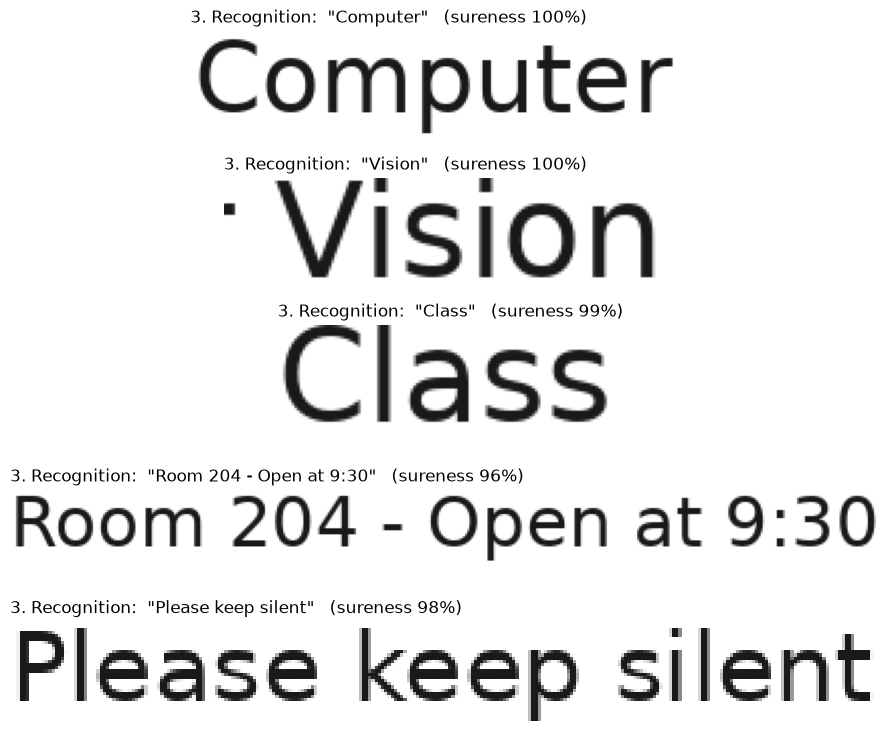

Total time: 1126 ms for the whole pipeline


In [4]:
FONT_PATH = font_manager.findfont("DejaVu Sans")      # a font that always exists with matplotlib


def render_text(lines, width=720, background=(255, 255, 255)):
    """Draws lines of text on a blank picture. lines = [(text, font_size), ...]"""
    height = sum(size + 26 for _, size in lines) + 30
    picture = Image.new("RGB", (width, height), background)
    draw = ImageDraw.Draw(picture)
    y = 22
    for text, size in lines:
        draw.text((30, y), text, font=ImageFont.truetype(FONT_PATH, size), fill=(25, 25, 25))
        y += size + 26
    return picture


sign = render_text([("Computer Vision Class", 46), ("Room 204 - Open at 9:30", 34), ("Please keep silent", 30)])
sign_bgr = cv2.cvtColor(np.array(sign), cv2.COLOR_RGB2BGR)

ocr.read(sign_bgr)                                     # warm-up (the first call is always slower)
t0 = time.perf_counter()
sign_lines = ocr.read(sign_bgr)
sign_seconds = time.perf_counter() - t0

# Stage 1 and 2: input and detection
boxed = sign_bgr.copy()
for box, text, conf in sign_lines:
    cv2.polylines(boxed, [box.astype(np.int32)], True, (0, 160, 0), 3)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
axes[0].imshow(sign)
axes[0].set_title("1. Input")
axes[1].imshow(boxed[:, :, ::-1])
axes[1].set_title(f"2. Detection: {len(sign_lines)} text lines found")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Stage 3: every box is cropped and read
ordered = sorted(sign_lines, key=lambda line: line[0][:, 1].min())
if ordered:
    fig, axes = plt.subplots(len(ordered), 1, figsize=(9, 1.5 * len(ordered)))
    for ax, (box, text, conf) in zip(np.atleast_1d(axes), ordered):
        x1, y1 = np.maximum(box.min(axis=0).astype(int), 0)
        x2, y2 = box.max(axis=0).astype(int)
        ax.imshow(sign_bgr[y1:y2, x1:x2][:, :, ::-1])
        ax.set_title(f'3. Recognition:  "{text}"   (sureness {conf:.0%})', fontsize=12, loc="left")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print(f"Total time: {sign_seconds * 1000:.0f} ms for the whole pipeline")
else:
    print("No text was found.")

## Step 4: OCR metrics

Reading is easy to evaluate **when the true text is known**.

| Metric | Question | How it is computed | Better when |
|---|---|---|---|
| **CER** (Character Error Rate) | What share of the characters is wrong? | Edit distance divided by the number of true characters | **Lower** (0% = perfect) |
| **WER** (Word Error Rate) | What share of the words is wrong? | Same idea, counted in words | **Lower** |
| **Confidence** | How sure is the model? | Score given by the model itself | Higher, but it is **not** correctness |
| **Latency** | How long does one picture take? | Milliseconds per picture | Lower |

**Edit distance** is the minimum number of single edits (insert a character, delete a character, replace a character) needed to turn the
recognized text into the true text. Example: "hallo" instead of "hello" needs 1 replacement. With 5 true characters, **CER = 1 / 5 = 20%**.

**Live camera.** Without the true text, a webcam can only show latency, confidence, and the number of lines.
If the text in front of the camera is known (printed on purpose), it can be typed into `EXPECTED_TEXT` and the live error rate becomes available.

**Robustness test.** The cell below measures CER and WER on 6 phrases under 6 conditions that happen in real life:
clean, blurry, noisy, low contrast, rotated, and tiny text.

CER('hello', 'hallo') = 20%
WER('the cat sat on the mat', 'the cat sit on the mat') = 16.7%


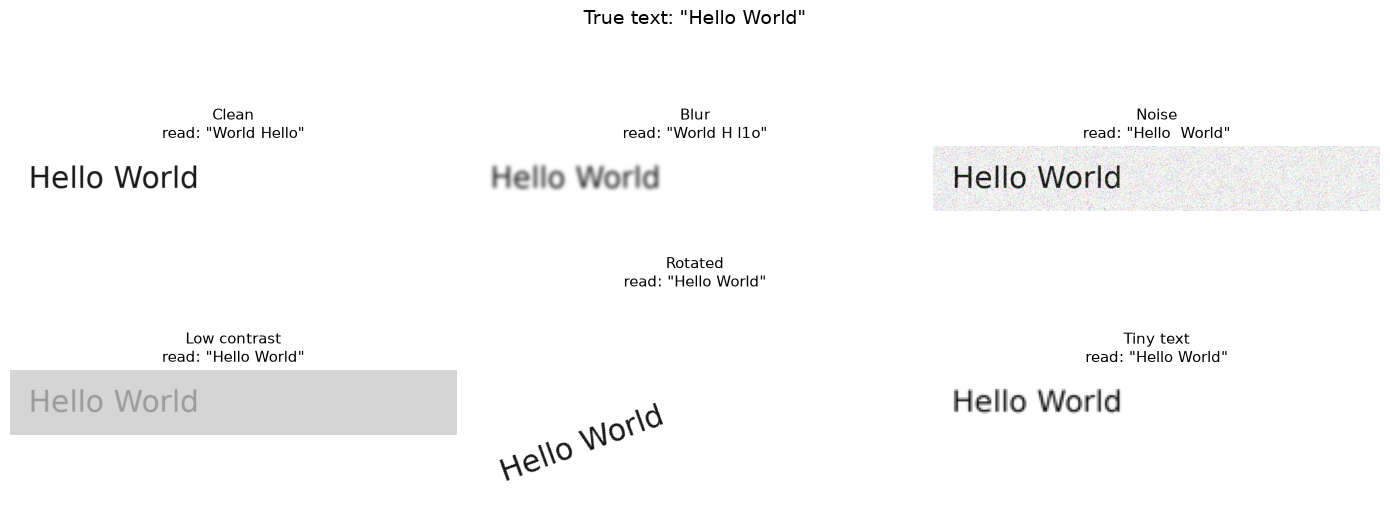

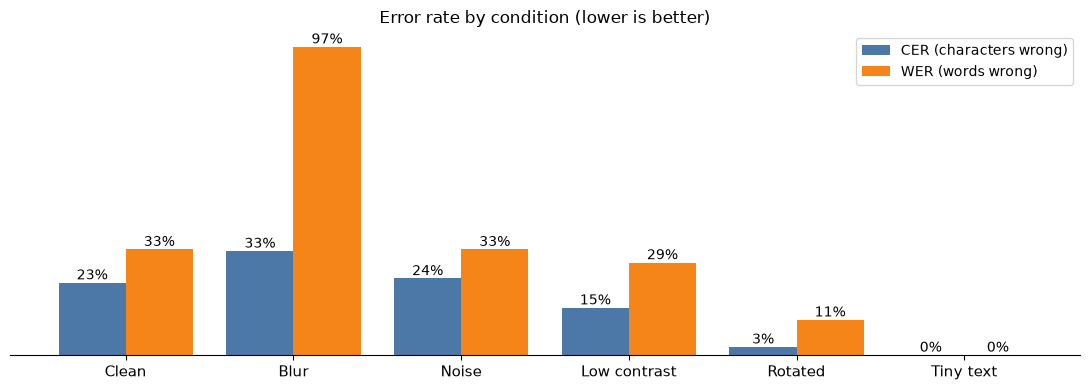

Condition         CER    WER   Confidence  Time (ms)
Clean             23%    33%          99%       2315
Blur              33%    97%          94%       2061
Noise             24%    33%          95%       2038
Low contrast      15%    29%          99%       1995
Rotated            3%    11%          97%        650
Tiny text          0%     0%         100%       2452


In [5]:
def edit_distance(a, b):
    """Minimum number of insertions, deletions, and replacements to turn a into b."""
    previous = list(range(len(b) + 1))
    for i, item_a in enumerate(a, start=1):
        current = [i]
        for j, item_b in enumerate(b, start=1):
            cost = 0 if item_a == item_b else 1
            current.append(min(previous[j] + 1, current[j - 1] + 1, previous[j - 1] + cost))
        previous = current
    return previous[-1]


def cer(reference, recognized):
    return edit_distance(reference, recognized) / max(len(reference), 1)


def wer(reference, recognized):
    reference_words = reference.split()
    return edit_distance(reference_words, recognized.split()) / max(len(reference_words), 1)


def full_text(lines):
    """Joins the recognized lines in reading order (top to bottom, then left to right)."""
    ordered_lines = sorted(lines, key=lambda l: (round(float(l[0][:, 1].mean()) / 20), float(l[0][:, 0].min())))
    return " ".join(l[1] for l in ordered_lines)


print(f"CER('hello', 'hallo') = {cer('hello', 'hallo'):.0%}")
print(f"WER('the cat sat on the mat', 'the cat sit on the mat') = {wer('the cat sat on the mat', 'the cat sit on the mat'):.1%}")

# ---- Robustness test
rng = np.random.default_rng(0)

def add_noise(picture):
    pixels = np.asarray(picture).astype(np.float32) + rng.normal(0, 45, (picture.height, picture.width, 3))
    return Image.fromarray(np.clip(pixels, 0, 255).astype(np.uint8))

conditions = {
    "Clean": lambda im: im,
    "Blur": lambda im: im.filter(ImageFilter.GaussianBlur(3)),
    "Noise": add_noise,
    "Low contrast": lambda im: Image.blend(im, Image.new("RGB", im.size, (200, 200, 200)), 0.75),
    "Rotated": lambda im: im.rotate(20, expand=True, fillcolor=(255, 255, 255)),
    "Tiny text": lambda im: im.resize((max(1, int(im.width * 0.3)), max(1, int(im.height * 0.3)))),
}
phrases = ["Hello World", "Computer Vision", "Room 204 Open", "Stable Diffusion", "Object Tracking 101", "Welcome to the demo"]

results = {name: {"cer": [], "wer": [], "conf": [], "ms": []} for name in conditions}
first_phrase_reads = {}

for phrase in phrases:
    clean = render_text([(phrase, 48)])
    for name, change in conditions.items():
        picture = change(clean)
        t0 = time.perf_counter()
        lines = ocr.read(cv2.cvtColor(np.array(picture), cv2.COLOR_RGB2BGR))
        results[name]["ms"].append((time.perf_counter() - t0) * 1000)
        recognized = full_text(lines)
        results[name]["cer"].append(cer(phrase, recognized))
        results[name]["wer"].append(wer(phrase, recognized))
        results[name]["conf"].append(np.mean([l[2] for l in lines]) if lines else 0.0)
        if phrase == phrases[0]:
            first_phrase_reads[name] = (picture, recognized)

# What the OCR read for the first phrase, under each condition
fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
for ax, (name, (picture, recognized)) in zip(axes.ravel(), first_phrase_reads.items()):
    ax.imshow(picture)
    ax.axis("off")
    ax.set_title(f'{name}\nread: "{recognized}"', fontsize=11)
fig.suptitle(f'True text: "{phrases[0]}"', fontsize=14)
plt.tight_layout()
plt.show()

# Scores per condition
names = list(conditions)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(11, 4))
bars1 = ax.bar(x - 0.2, [np.mean(results[n]["cer"]) * 100 for n in names], 0.4, label="CER (characters wrong)", color="#4C78A8")
bars2 = ax.bar(x + 0.2, [np.mean(results[n]["wer"]) * 100 for n in names], 0.4, label="WER (words wrong)", color="#F58518")
ax.bar_label(bars1, fmt="%.0f%%")
ax.bar_label(bars2, fmt="%.0f%%")
ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=11)
ax.set_yticks([])
ax.set_title("Error rate by condition (lower is better)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'Condition':<14}{'CER':>7}{'WER':>7}{'Confidence':>13}{'Time (ms)':>11}")
for name in names:
    r = results[name]
    print(f"{name:<14}{np.mean(r['cer']):>7.0%}{np.mean(r['wer']):>7.0%}{np.mean(r['conf']):>13.0%}{np.mean(r['ms']):>11.0f}")

## Step 5: Live OCR on the webcam

**Set-up for a good reading**

- Hold a printed page, a book, a phone screen, or a sign about 30 to 50 cm from the camera.
- Good light and large, steady text work best. Printed Latin text is read well, handwriting is much harder.
- **Q** (or Esc) closes the window.

**What appears on the screen**

- A **green box** around every text line, with the recognized text and its **confidence**
- A panel with **FPS**, **OCR time**, the **number of lines**, and the **average confidence**
- If `EXPECTED_TEXT` is filled in: a live **CER** against the true text

The AI reads one frame out of `OCR_EVERY_N_FRAMES`. At the end, the cell prints the lines that were read most often during the session.

In [6]:
FONT = cv2.FONT_HERSHEY_SIMPLEX


def open_camera():
    cap = cv2.VideoCapture(CAMERA_INDEX)
    if not cap.isOpened():
        raise RuntimeError(
            "Cannot open the camera. Check: (1) camera permission for VS Code, "
            "(2) no other app is using the camera, (3) try CAMERA_INDEX = 1."
        )
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)
    return cap


def take_photo():
    """One picture from the camera (the first frames are dark, so they are skipped). Not mirrored."""
    cap = open_camera()
    time.sleep(0.5)
    ok = False
    for _ in range(5):
        ok, photo = cap.read()
    cap.release()
    return photo if ok else None


def show_frame(frame, title):
    """Shows one picture. Returns True if the user asked to stop."""
    if DISPLAY_MODE == "window":
        cv2.imshow(title, frame)
        return cv2.waitKey(1) & 0xFF in (ord("q"), ord("Q"), 27)
    clear_output(wait=True)
    display(NotebookImage(data=cv2.imencode(".jpg", frame)[1].tobytes()))
    return False


def close_camera(cap):
    cap.release()
    cv2.destroyAllWindows()
    for _ in range(4):
        cv2.waitKey(1)


def draw_panel(frame, lines, width=340):
    overlay = frame.copy()
    cv2.rectangle(overlay, (10, 10), (10 + width, 26 + 24 * len(lines)), (0, 0, 0), -1)
    cv2.addWeighted(overlay, 0.55, frame, 0.45, 0, frame)
    for i, text in enumerate(lines):
        cv2.putText(frame, text, (20, 36 + 24 * i), FONT, 0.6, (255, 255, 255), 1, cv2.LINE_AA)


def run_live_ocr():
    cap = open_camera()
    lines = []                       # last result: (box, text, confidence) in full-size coordinates
    seen = Counter()
    frame_number, fps, ocr_ms = 0, 0.0, 0.0
    start = last_time = time.time()

    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frame_number += 1

            # The AI reads only one frame out of N
            if (frame_number - 1) % OCR_EVERY_N_FRAMES == 0:
                scale = OCR_WIDTH / frame.shape[1]
                small = cv2.resize(frame, (OCR_WIDTH, int(frame.shape[0] * scale)))
                t0 = time.perf_counter()
                found = ocr.read(small)
                ocr_ms = (time.perf_counter() - t0) * 1000
                lines = [(box / scale, text, conf) for box, text, conf in found if conf >= MIN_CONFIDENCE]
                for _, text, _ in lines:
                    seen[text] += 1

            # Draw the boxes and the recognized text
            for box, text, conf in lines:
                points = box.astype(np.int32)
                cv2.polylines(frame, [points], True, (0, 220, 0), 2)
                tag = f"{text} {conf:.0%}".encode("ascii", "ignore").decode()      # OpenCV draws ASCII only
                x, y = max(int(points[:, 0].min()), 0), int(points[:, 1].min())
                (w, h), _ = cv2.getTextSize(tag, FONT, 0.6, 1)
                top = max(y - h - 10, 0)
                cv2.rectangle(frame, (x, top), (x + w + 8, top + h + 10), (0, 220, 0), -1)
                cv2.putText(frame, tag, (x + 4, top + h + 3), FONT, 0.6, (0, 0, 0), 1, cv2.LINE_AA)

            # Live information
            now = time.time()
            current_fps = 1.0 / max(now - last_time, 1e-6)
            fps = current_fps if fps == 0 else 0.9 * fps + 0.1 * current_fps
            last_time = now

            info = [
                f"Frame: {frame_number}",
                f"FPS: {fps:.1f}",
                f"OCR time: {ocr_ms:.0f} ms (every {OCR_EVERY_N_FRAMES} frames)",
                f"Text lines: {len(lines)}",
                f"Avg confidence: {np.mean([l[2] for l in lines]) if lines else 0:.0%}",
            ]
            if EXPECTED_TEXT:
                info.append(f"CER vs expected text: {cer(EXPECTED_TEXT, full_text(lines)):.0%}")
            info.append("Press Q to quit")
            draw_panel(frame, info)

            if show_frame(frame, "Live OCR  (press Q to quit)"):
                break
            if MAX_SECONDS and now - start > MAX_SECONDS:
                break

    except KeyboardInterrupt:
        print("Stopped by the user.")
    finally:
        close_camera(cap)

    print("----- Session report -----")
    print(f"Frames: {frame_number}, average FPS: {frame_number / max(time.time() - start, 1e-6):.1f}")
    print("Text read most often:")
    for text, count in seen.most_common(8):
        print(f"   {count:>3} x  {text}")


run_live_ocr()

QFontDatabase: Cannot find font directory /home/mdev/Dev/school/computer_vision_notebooks/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/mdev/Dev/school/computer_vision_notebooks/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/mdev/Dev/school/computer_vision_notebooks/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fonts.github.io/ for example) or switch to fontconfig.
QFontDatabase: Cannot find font directory /home/mdev/Dev/school/computer_vision_notebooks/.venv/lib/python3.12/site-packages/cv2/qt/fonts.
Note that Qt no longer ships fonts. Deploy some (from https://dejavu-fon

----- Session report -----
Frames: 124, average FPS: 4.8
Text read most often:
     5 x  WhatsApp
     2 x  Master Data & IA
     2 x  hatsApp
     1 x  RO
     1 x  Bo
     1 x  INPT COMITX.SPORT 2026/2027
     1 x  Mester Data &IA
     1 x  Mester Data & IA


# Part 2: Image captioning (CNN + LSTM)

**Image captioning** writes one sentence that describes a picture. It requires two skills: **seeing** (vision) and **writing** (language).
The classic architecture, **"Show and Tell"** (Google, 2015), gives one network to each skill:

| Part | Analogy | Job |
|---|---|---|
| **CNN** (encoder) | The **eyes** | Turns the picture into a short vector of numbers that summarizes its content |
| **LSTM** (decoder) | The **writer with a memory** | Writes the sentence **one word at a time** |

## What is an LSTM?

An **LSTM** (Long Short-Term Memory) is a network made for **sequences**. It reads one item at a time and keeps a **memory**
(a list of numbers) that is updated after every item. Three small "gates" decide what to **forget**, what to **store**, and what to **output**.
A storyteller is a good analogy: after saying "a big red", the storyteller remembers it and knows that a shape must come next, not "on".

## The architecture

```
 Picture --> [ CNN ] --> picture vector --> LSTM step 0  (the LSTM "looks" at the picture)
                                                |
 <start> --> [ word -> numbers ] --> LSTM step 1 --> [ probability of every word ] --> "a"
    a    --> [ word -> numbers ] --> LSTM step 2 --> [ probability of every word ] --> "big"
   big   --> [ word -> numbers ] --> LSTM step 3 --> [ probability of every word ] --> "red"
   ...                                                                                  ...
  left   --> [ word -> numbers ] --> LSTM step 8 --> [ probability of every word ] --> <end>
```

## Special tokens

| Token | Meaning |
|---|---|
| `<start>` | The signal "begin the sentence". The first word is predicted after it |
| `<end>` | The signal "the sentence is finished". Generation stops when it is predicted |
| `<pad>` | Filler used to give all sentences the same length during training. Ignored by the loss |

Every word of the **vocabulary** (the list of all known words) has an ID number. The model never sees letters, only these IDs.

## How a caption is written (inference)

1. The CNN converts the picture to a vector. The LSTM reads it.
2. The token `<start>` is given to the LSTM.
3. The LSTM outputs **one score per word of the vocabulary**. A softmax turns them into **probabilities** that add up to 100%.
4. A word is chosen: the most probable one (**greedy**), a random one following the probabilities (**sampling**),
   or the best of several candidate sentences kept in parallel (**beam search**).
5. The chosen word becomes the **next input**.
6. Steps 3 to 5 repeat until `<end>` is predicted.

## How the model is trained

The model is shown a picture with a **real** caption. At every position, it must guess the **next real word**.
This is **teacher forcing**: the correct previous word is always given as input, even if the model would have guessed another one.
The **loss** (cross-entropy) measures how surprised the model is by the real next word. Training lowers this surprise.

## The toy world used here

Real datasets (Flickr8k, COCO) hold thousands of photos with 5 human captions each, and training takes hours.
To train in about 2 minutes on a laptop CPU, and to make **every step visible**, this notebook uses a **small world**:
one colored shape on a gray background. The architecture is the same as for real photos, only the data is simpler.

Each picture has **3 reference captions** with different wording, as real datasets have several. The model must learn that
several sentences can be correct.

| Setting (next cell) | Meaning |
|---|---|
| `TRAIN_IMAGES` / `TEST_IMAGES` | Pictures used to train the model, and new pictures used to test it |
| `EPOCHS` | How many times the model goes through the whole training set |
| `FORCE_RETRAIN` | `True` ignores the saved weights and trains again |
| `RUN_REAL_CAPTIONER` | `True` runs the optional bonus with a real captioning model |

Vocabulary: 22 tokens -> ['<pad>', '<start>', '<end>', 'a', 'at', 'big', 'blue', 'bottom', 'circle', 'green', 'is', 'left', 'on', 'red', 'right', 'small', 'square', 'the', 'there', 'top', 'triangle', 'yellow']
Training: 2000 pictures x 3 captions = 6000 pairs. Test: 300 new pictures.

Caption : a big red circle on the left
Tokens  : <start> a big red circle on the left <end> <pad> <pad>
IDs     : [1, 3, 5, 13, 8, 12, 17, 11, 2, 0, 0]


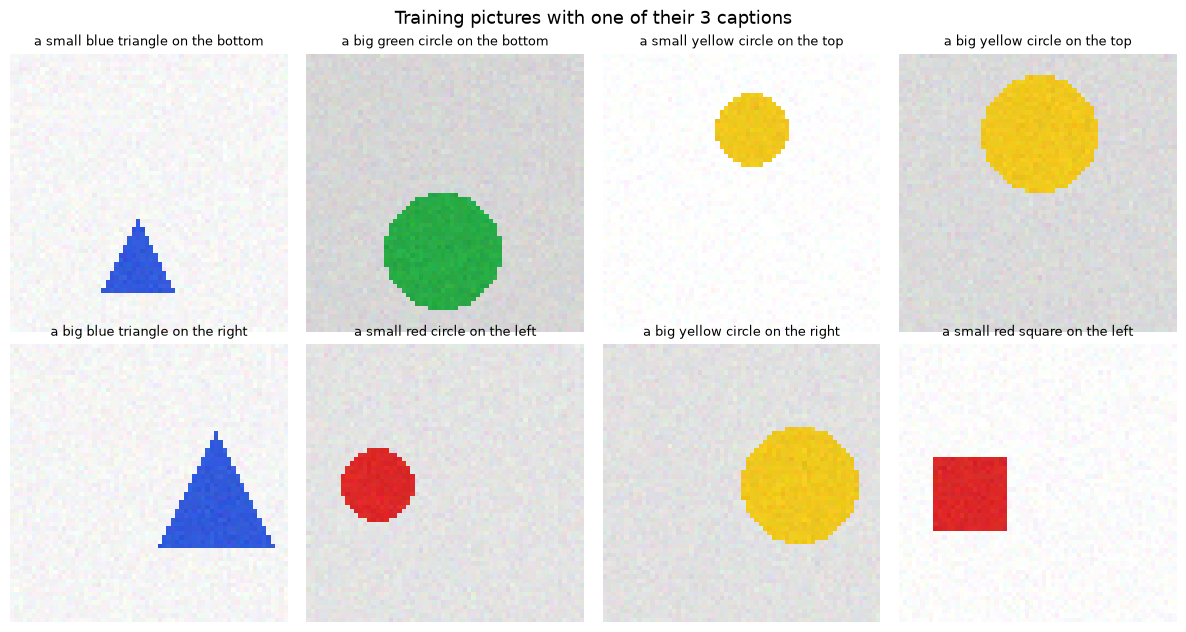

In [13]:
TRAIN_IMAGES       = 2000
TEST_IMAGES        = 300
EPOCHS             = 30
FORCE_RETRAIN      = False      # True = ignore the saved weights and train again
RUN_REAL_CAPTIONER = True      # True = bonus at the end of Part 2 (downloads about 1 GB)

COLORS    = {"red": (220, 40, 40), "green": (40, 170, 70), "blue": (50, 90, 220), "yellow": (240, 200, 30)}
SHAPES    = ["circle", "square", "triangle"]
SIZES     = {"small": 8, "big": 13}                       # radius in pixels
POSITIONS = {"left": (16, 32), "right": (48, 32), "top": (32, 16), "bottom": (32, 48)}


def captions_for(size, color, shape, position):
    """The 3 reference captions of one picture."""
    return [
        f"a {size} {color} {shape} on the {position}",
        f"there is a {size} {color} {shape} at the {position}",
        f"a {color} {shape} is on the {position}",
    ]


def draw_shape(draw, shape, cx, cy, r, color):
    if shape == "circle":
        draw.ellipse([cx - r, cy - r, cx + r, cy + r], fill=color)
    elif shape == "square":
        draw.rectangle([cx - r, cy - r, cx + r, cy + r], fill=color)
    else:
        draw.polygon([(cx, cy - r), (cx - r, cy + r), (cx + r, cy + r)], fill=color)


def make_sample(rng):
    """One random picture (64 x 64) and the truth about it."""
    pick = lambda options: list(options)[int(rng.integers(len(options)))]
    size, color, shape, position = pick(SIZES), pick(COLORS), pick(SHAPES), pick(POSITIONS)
    cx, cy = POSITIONS[position]
    cx, cy = cx + int(rng.integers(-3, 4)), cy + int(rng.integers(-3, 4))      # small random shift
    gray = int(rng.integers(205, 256))
    picture = Image.new("RGB", (64, 64), (gray, gray, gray))
    draw_shape(ImageDraw.Draw(picture), shape, cx, cy, SIZES[size], COLORS[color])
    pixels = np.asarray(picture).astype(np.float32) + rng.normal(0, 5, (64, 64, 3))   # a little camera noise
    return np.clip(pixels, 0, 255).astype(np.uint8), {"size": size, "color": color, "shape": shape, "position": position}


# ---- Vocabulary: every word that can appear, with an ID number
all_words = set()
for s in SIZES:
    for c in COLORS:
        for sh in SHAPES:
            for p in POSITIONS:
                for caption in captions_for(s, c, sh, p):
                    all_words.update(caption.split())

vocab = ["<pad>", "<start>", "<end>"] + sorted(all_words)
word_to_id = {word: i for i, word in enumerate(vocab)}
PAD, START, END = 0, 1, 2
MAX_LEN = len(captions_for("big", "red", "circle", "left")[1].split()) + 2          # longest sentence + <start> + <end>


def encode_caption(text):
    ids = [START] + [word_to_id[w] for w in text.split()] + [END]
    return ids + [PAD] * (MAX_LEN - len(ids))


def build_dataset(n, seed):
    rng = np.random.default_rng(seed)
    samples = [make_sample(rng) for _ in range(n)]
    images = torch.tensor(np.stack([s[0] for s in samples])).permute(0, 3, 1, 2).float() / 255
    return images, [s[1] for s in samples]


train_images, train_attrs = build_dataset(TRAIN_IMAGES, seed=1)
test_images, test_attrs = build_dataset(TEST_IMAGES, seed=2)

# Training pairs: every picture is paired with each of its 3 captions
pair_image_index, pair_captions = [], []
for i, a in enumerate(train_attrs):
    for text in captions_for(a["size"], a["color"], a["shape"], a["position"]):
        pair_image_index.append(i)
        pair_captions.append(encode_caption(text))
pair_image_index = torch.tensor(pair_image_index)
pair_captions = torch.tensor(pair_captions)

print(f"Vocabulary: {len(vocab)} tokens ->", vocab)
print(f"Training: {TRAIN_IMAGES} pictures x 3 captions = {len(pair_captions)} pairs. Test: {TEST_IMAGES} new pictures.\n")

example = captions_for("big", "red", "circle", "left")[0]
example_ids = encode_caption(example)
print("Caption :", example)
print("Tokens  :", " ".join(vocab[i] for i in example_ids))
print("IDs     :", example_ids)

fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, i in zip(axes.ravel(), range(8)):
    a = train_attrs[i]
    ax.imshow(train_images[i].permute(1, 2, 0))
    ax.axis("off")
    ax.set_title(captions_for(a["size"], a["color"], a["shape"], a["position"])[0], fontsize=9)
fig.suptitle("Training pictures with one of their 3 captions", fontsize=13)
plt.tight_layout()
plt.show()

## Step 6: The model

| Layer | Output shape | Role |
|---|---|---|
| Input picture | 3 x 64 x 64 | Red, green, and blue values of every pixel |
| 3 x (Convolution + ReLU + MaxPool) | 64 x 8 x 8 | Filters detect edges, colors, and shapes. Every pooling halves the picture size |
| Convolution + average pooling to 4 x 4 | 64 x 4 x 4 | A coarse map of **where** things are (needed for "left" or "top") |
| Linear | 128 | The **picture vector** |
| Word embedding | 128 | Every word ID becomes 128 numbers that carry its meaning |
| **LSTM** | 256 (memory) | Reads the picture vector, then one word at a time |
| Linear + softmax | 22 | A probability for each word of the vocabulary |

**Real-world version.** The CNN is a large network already trained on millions of photos (ResNet, Inception),
and the vocabulary has thousands of words. Here, a small CNN is trained together with the LSTM.

In [14]:
class Captioner(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super().__init__()
        # ---- Encoder: the CNN (the eyes)
        def block(inputs, outputs):
            return [nn.Conv2d(inputs, outputs, 3, padding=1), nn.BatchNorm2d(outputs), nn.ReLU(), nn.MaxPool2d(2)]

        self.cnn = nn.Sequential(
            *block(3, 16),                                   # 64 x 64 -> 32 x 32
            *block(16, 32),                                  # -> 16 x 16
            *block(32, 64),                                  # -> 8 x 8
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d(4),                         # -> 4 x 4 (a coarse map of the picture)
        )
        self.to_embedding = nn.Linear(64 * 4 * 4, embed_dim)

        # ---- Decoder: the LSTM (the writer)
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.to_vocab = nn.Linear(hidden_dim, vocab_size)

    def encode(self, images):
        """Picture -> picture vector."""
        return self.to_embedding(self.cnn(images).flatten(1))

    def forward(self, images, words_in):
        """Used for training: the picture, then the words of the real caption."""
        picture_vector = self.encode(images).unsqueeze(1)             # step 0: the picture
        word_vectors = self.embedding(words_in)                       # steps 1, 2, 3...: the words
        outputs, _ = self.lstm(torch.cat([picture_vector, word_vectors], dim=1))
        return self.to_vocab(outputs[:, 1:])                          # one prediction per word position


model = Captioner(len(vocab))

cnn_params = sum(p.numel() for p in list(model.cnn.parameters()) + list(model.to_embedding.parameters()))
lstm_params = sum(p.numel() for p in list(model.embedding.parameters()) + list(model.lstm.parameters()) + list(model.to_vocab.parameters()))
print(f"CNN (eyes)                 : {cnn_params:>9,} parameters")
print(f"Embedding + LSTM (writer)  : {lstm_params:>9,} parameters")

CNN (eyes)                 :   192,064 parameters
Embedding + LSTM (writer)  :   403,734 parameters


## Step 7: Training

The loop repeats for every batch of 64 (picture, caption) pairs:

1. The picture and the caption **without its last token** go into the model.
2. The model predicts the next word at every position.
3. The loss compares the predictions with the real caption **shifted by one word**.
4. The weights are adjusted slightly to lower the loss.

A model that guesses randomly has a loss of about ln(vocabulary size). The curve should fall far below this reference.
Trained weights are saved to `captioner.pt` and reloaded next time, so that training happens only once.

Trained weights loaded from captioner.pt (FORCE_RETRAIN = True trains again).


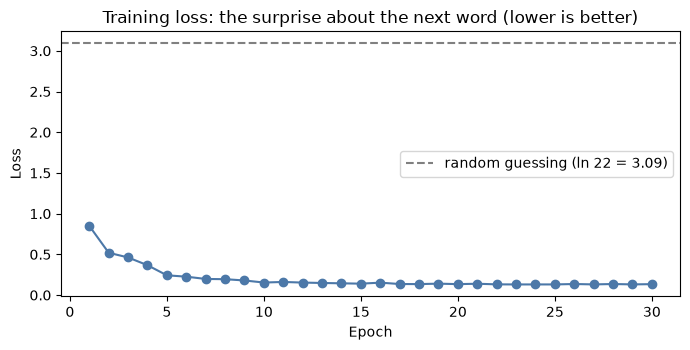

In [15]:
BATCH_SIZE = 64
LEARNING_RATE = 2e-3
WEIGHTS_FILE = Path("captioner.pt")

losses = []
if WEIGHTS_FILE.exists() and not FORCE_RETRAIN:
    saved = torch.load(WEIGHTS_FILE)
    model.load_state_dict(saved["weights"])
    losses = saved["losses"]
    print(f"Trained weights loaded from {WEIGHTS_FILE} (FORCE_RETRAIN = True trains again).")
else:
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    n_pairs = len(pair_captions)
    start = time.time()
    model.train()
    for epoch in range(EPOCHS):
        order = torch.randperm(n_pairs)
        epoch_loss = 0.0
        for i in range(0, n_pairs, BATCH_SIZE):
            batch = order[i:i + BATCH_SIZE]
            pictures = train_images[pair_image_index[batch]]
            captions = pair_captions[batch]

            predictions = model(pictures, captions[:, :-1])                    # input: <start> w1 w2 ...
            loss = F.cross_entropy(predictions.reshape(-1, len(vocab)),        # target: w1 w2 ... <end>
                                   captions[:, 1:].reshape(-1), ignore_index=PAD)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(batch)
        losses.append(epoch_loss / n_pairs)
        if epoch % 5 == 0 or epoch == EPOCHS - 1:
            print(f"Epoch {epoch + 1:>2}/{EPOCHS}   loss {losses[-1]:.3f}   ({time.time() - start:.0f} s)")
    torch.save({"weights": model.state_dict(), "losses": losses}, WEIGHTS_FILE)

model.eval()

plt.figure(figsize=(7, 3.6))
plt.plot(range(1, len(losses) + 1), losses, marker="o", color="#4C78A8")
plt.axhline(np.log(len(vocab)), color="gray", linestyle="--", label=f"random guessing (ln {len(vocab)} = {np.log(len(vocab)):.2f})")
plt.title("Training loss: the surprise about the next word (lower is better)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

## Step 8: Writing a caption, word by word

The cell below follows the 6 steps of inference on a **new picture** that the model has never seen, and shows what happens at each word:

- **Input**: the word given to the LSTM (starting with `<start>`)
- **Top 5 probabilities**: the 5 most likely next words. The **green** bar is the chosen word
- **Memory**: the 256 numbers of the LSTM memory after each word. The pattern changes as the sentence grows

The first probabilities show the **three wordings** learned from the data, for example "a" against "there".
The following words are mostly decided by the **picture**: color, shape, size, and position.

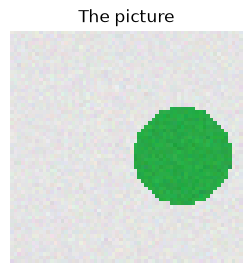

Step  Input       Top predictions                                 Chosen
1     <start>     a 74%, there 26%, circle 0%                     a
2     a           big 50%, green 50%, yellow 0%                   big
3     big         green 100%, yellow 0%, blue 0%                  green
4     green       circle 100%, triangle 0%, square 0%             circle
5     circle      on 100%, is 0%, right 0%                        on
6     on          the 100%, right 0%, on 0%                       the
7     the         right 100%, top 0%, left 0%                     right
8     right       <end> 100%, right 0%, the 0%                    <end>

Caption: a big green circle on the right
Truth  : big green circle on the right


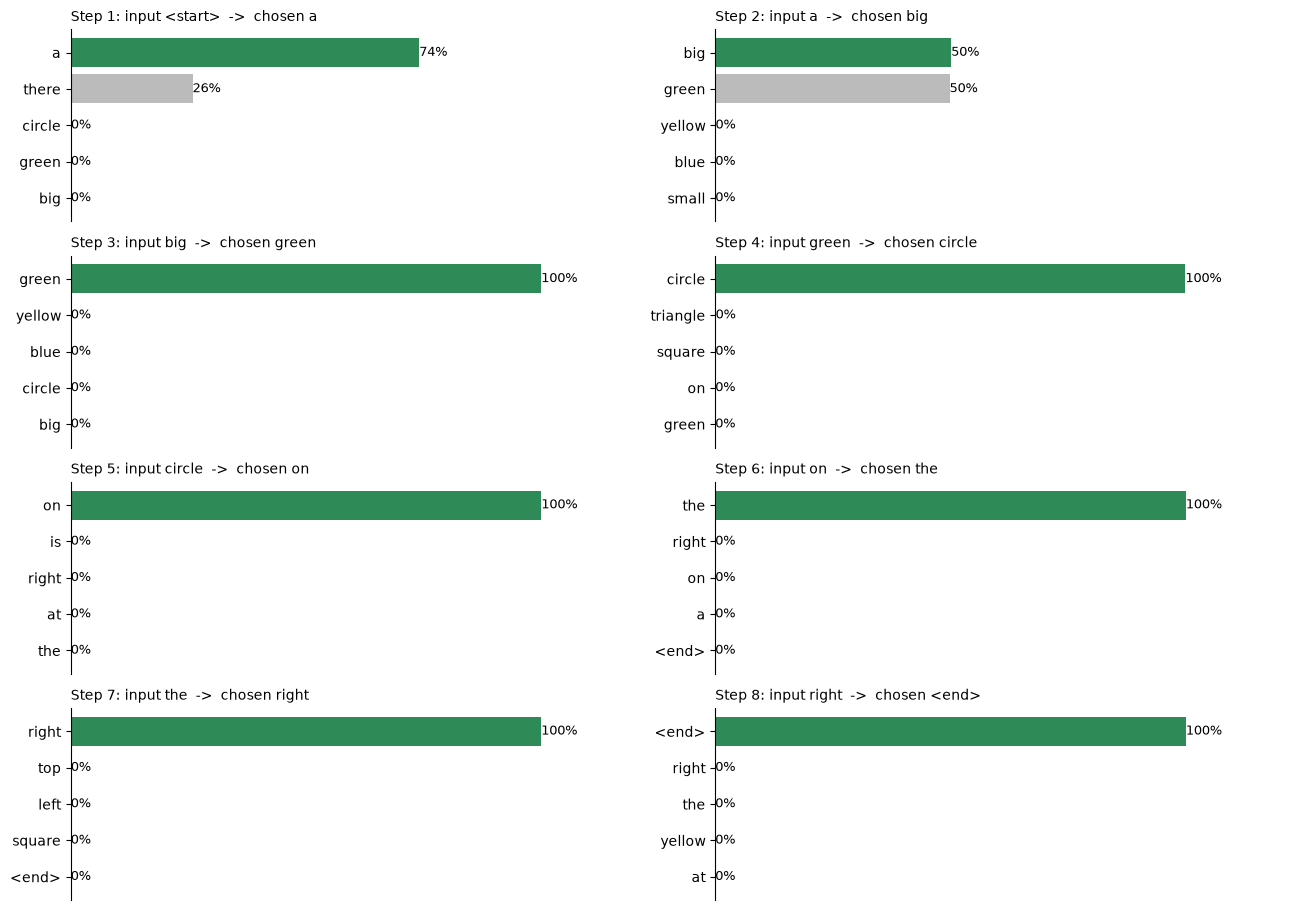

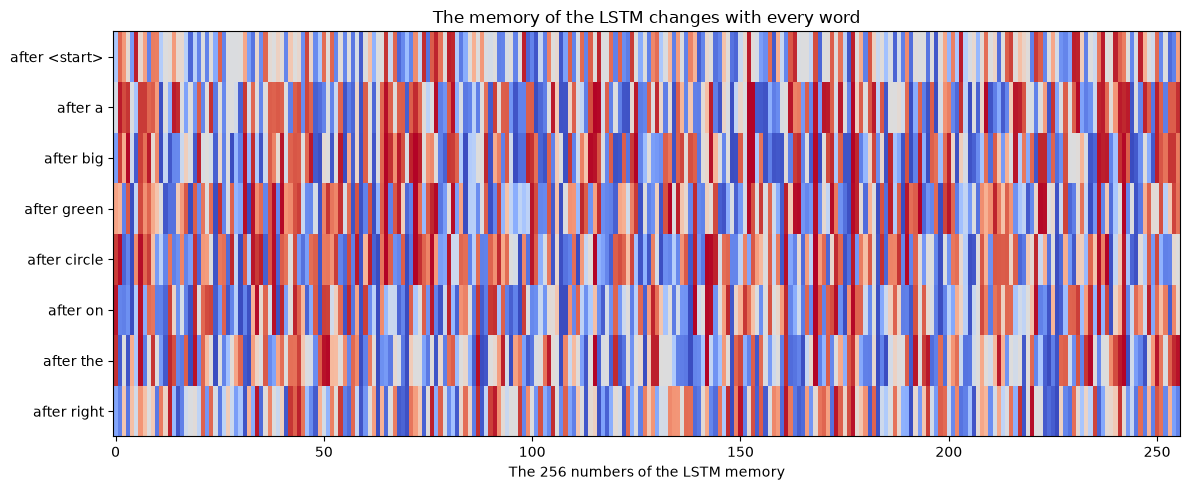

In [16]:
@torch.no_grad()
def caption_step_by_step(model, picture, sample=False):
    """Writes a caption word by word. Returns the words and a record of every step."""
    model.eval()
    picture_vector = model.encode(picture.unsqueeze(0)).unsqueeze(1)
    _, state = model.lstm(picture_vector)                   # step 0: the LSTM reads the picture

    word, words, steps = START, [], []
    for _ in range(MAX_LEN):
        embedded = model.embedding(torch.tensor([[word]]))
        output, state = model.lstm(embedded, state)         # the LSTM reads one word and updates its memory
        probabilities = F.softmax(model.to_vocab(output[:, 0]), dim=-1)[0]
        best = probabilities.topk(5)

        chosen = int(torch.multinomial(probabilities, 1)) if sample else int(probabilities.argmax())
        steps.append({
            "input": vocab[word],
            "top": [(vocab[i], p) for p, i in zip(best.values.tolist(), best.indices.tolist())],
            "chosen": vocab[chosen],
            "memory": state[0][0, 0].numpy().copy(),
        })
        if chosen == END:
            break
        words.append(vocab[chosen])
        word = chosen
    return words, steps


def explain_caption(picture, truth=None):
    words, steps = caption_step_by_step(model, picture)

    plt.figure(figsize=(3, 3.3))
    plt.imshow(picture.permute(1, 2, 0))
    plt.axis("off")
    plt.title("The picture", fontsize=12)
    plt.show()

    print(f"{'Step':<6}{'Input':<12}{'Top predictions':<48}{'Chosen'}")
    for number, step in enumerate(steps, start=1):
        top = ", ".join(f"{w} {p:.0%}" for w, p in step["top"][:3])
        print(f"{number:<6}{step['input']:<12}{top:<48}{step['chosen']}")
    print("\nCaption:", " ".join(words))
    if truth:
        print("Truth  :", f"{truth['size']} {truth['color']} {truth['shape']} on the {truth['position']}")

    # One small chart per step
    rows = (len(steps) + 1) // 2
    fig, axes = plt.subplots(rows, 2, figsize=(13, 2.3 * rows))
    axes = axes.ravel()
    for ax in axes:
        ax.axis("off")
    for ax, number, step in zip(axes, range(1, len(steps) + 1), steps):
        ax.axis("on")
        labels = [w for w, _ in step["top"]][::-1]
        values = [p for _, p in step["top"]][::-1]
        colors = ["#2E8B57" if w == step["chosen"] else "#BBBBBB" for w in labels]
        bars = ax.barh(labels, values, color=colors)
        ax.bar_label(bars, labels=[f"{v:.0%}" for v in values], fontsize=9)
        ax.set_xlim(0, 1.2)
        ax.set_xticks([])
        ax.spines[["top", "right", "bottom"]].set_visible(False)
        ax.set_title(f"Step {number}: input {step['input']}  ->  chosen {step['chosen']}", fontsize=10, loc="left")
    plt.tight_layout()
    plt.show()

    # The LSTM memory after each word
    memory = np.stack([s["memory"] for s in steps])
    fig, ax = plt.subplots(figsize=(12, 0.45 * len(steps) + 1.4))
    ax.imshow(memory, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)
    ax.set_yticks(range(len(steps)))
    ax.set_yticklabels([f"after {s['input']}" for s in steps])
    ax.set_xlabel("The 256 numbers of the LSTM memory")
    ax.set_title("The memory of the LSTM changes with every word")
    plt.tight_layout()
    plt.show()


EXAMPLE = 0
explain_caption(test_images[EXAMPLE], test_attrs[EXAMPLE])

**Greedy or sampling?** The cell above always takes the most probable word (**greedy**).
Taking a random word following the probabilities (**sampling**) gives different sentences for the same picture:
the wording changes, and sometimes an attribute becomes wrong when the model was not sure.

In [17]:
picture, truth = test_images[EXAMPLE], test_attrs[EXAMPLE]
print("Truth :", f"{truth['size']} {truth['color']} {truth['shape']} on the {truth['position']}")
print("Greedy:", " ".join(caption_step_by_step(model, picture)[0]))
print("Sampling, 5 tries:")
for _ in range(5):
    print("    ", " ".join(caption_step_by_step(model, picture, sample=True)[0]))

Truth : big green circle on the right
Greedy: a big green circle on the right
Sampling, 5 tries:
     a green circle is on the right
     a green circle is on the right
     a green circle is on the right
     a big green circle on the right
     a green circle is on the right


## Step 9: Captioning metrics

A caption has no single correct answer, so it is compared with several **reference captions** written by humans.

| Metric | Plain meaning | Note |
|---|---|---|
| **Loss** | The surprise about the next real word | Used during training |
| **BLEU-n** | The share of **n consecutive words** of the caption that also appear in a reference (from 0 to 1) | BLEU-1 checks vocabulary, BLEU-4 checks phrasing. Higher is better |
| **METEOR** | Like BLEU, but accepts synonyms and word forms | Explained only |
| **ROUGE-L** | Longest sequence of words shared with a reference | Explained only |
| **CIDEr** | Rewards words and phrases that many references share, and ignores very common words | Standard for the COCO dataset. Explained only |
| **SPICE** | Compares the objects, attributes, and relations described | Explained only |
| **Human opinion** | People rate the captions | The final judge |
| **Attribute accuracy** | The share of captions that name the **right color, shape, size, and position** | Possible **only in this toy world**, where the truth of every attribute is known |

**BLEU by hand.** Candidate: "a big red **square** on the left". Reference: "a big red **circle** on the left".
6 of the 7 words of the candidate appear in the reference, so **BLEU-1 = 6 / 7 = 86%**: one wrong word costs 14%.

**Limit of BLEU.** "a large crimson disk" is correct but scores low against "a big red circle", because BLEU counts words, not meaning.
This is why modern evaluations add CIDEr, SPICE, and human ratings.

**Real photos are harder.** In this toy world, scores are close to 100%. On real photos, BLEU-4 is typically between 0.2 and 0.4.

By hand: 6 of 7 words match -> BLEU-1 style precision = 86%



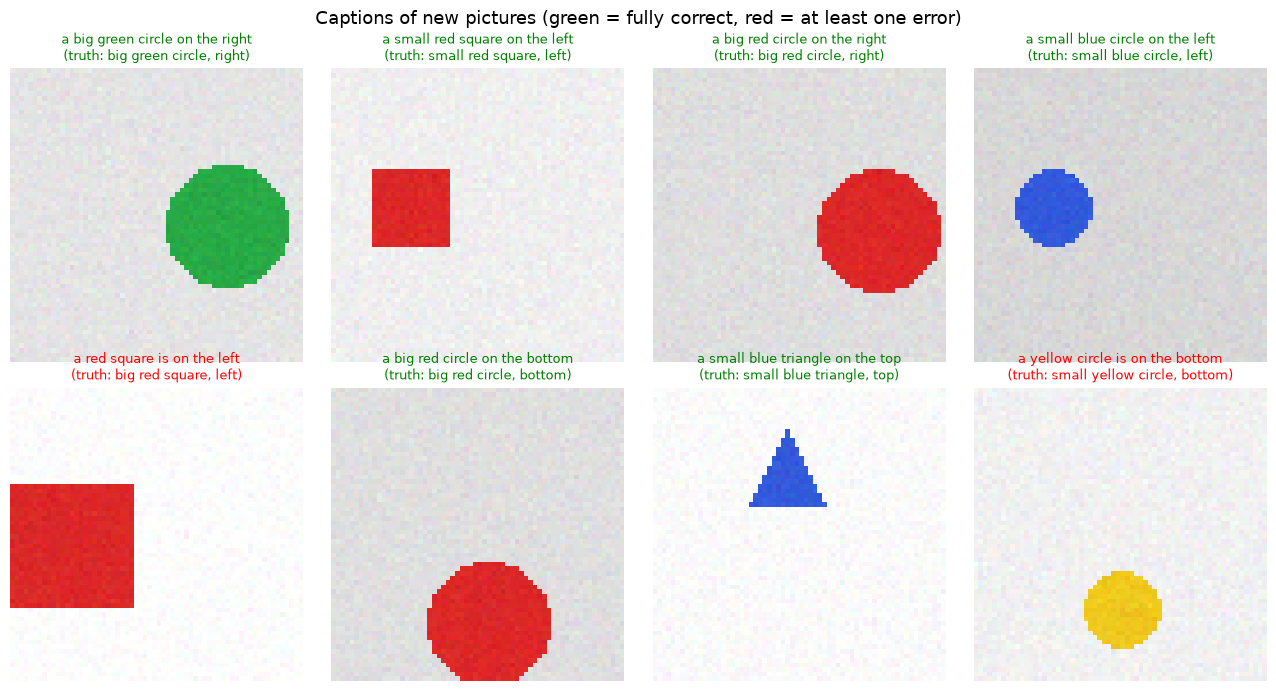

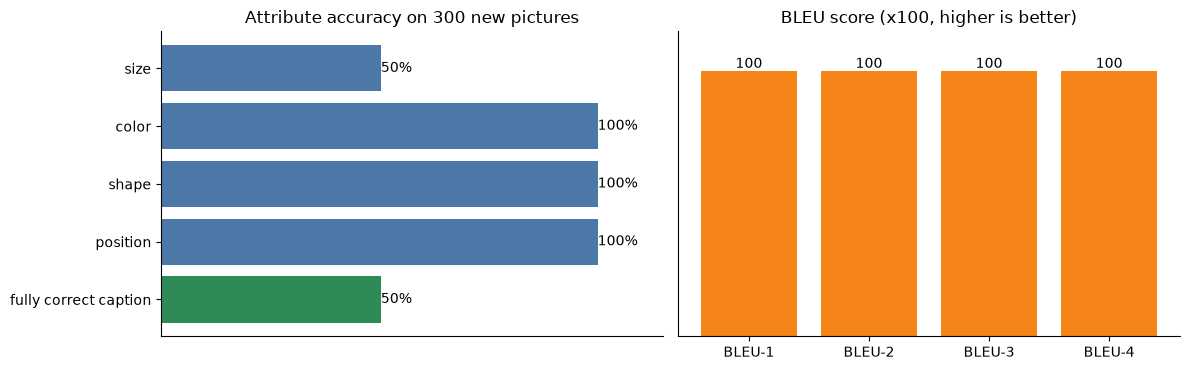

----- Report card -----
size                      50.3%
color                    100.0%
shape                    100.0%
position                 100.0%
fully correct caption     50.3%
BLEU-1                    1.00
BLEU-2                    1.00
BLEU-3                    1.00
BLEU-4                    1.00


In [18]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

# BLEU-1 by hand
candidate = "a big red square on the left".split()
reference = "a big red circle on the left".split()
matches = sum((Counter(candidate) & Counter(reference)).values())
print(f"By hand: {matches} of {len(candidate)} words match -> BLEU-1 style precision = {matches / len(candidate):.0%}\n")

# ---- Evaluation on the 300 test pictures
generated, references = [], []
attribute_names = [("size", SIZES), ("color", COLORS), ("shape", SHAPES), ("position", POSITIONS)]
attribute_hits = {name: 0 for name, _ in attribute_names}
perfect, outcomes = 0, []

for picture, attrs in zip(test_images, test_attrs):
    words, _ = caption_step_by_step(model, picture)
    generated.append(words)
    references.append([c.split() for c in captions_for(attrs["size"], attrs["color"], attrs["shape"], attrs["position"])])

    all_correct = True
    for name, options in attribute_names:
        found = [w for w in words if w in options]
        hit = found == [attrs[name]]
        attribute_hits[name] += hit
        all_correct = all_correct and hit
    perfect += all_correct
    outcomes.append(all_correct)

smooth = SmoothingFunction().method1
bleu = {
    "BLEU-1": corpus_bleu(references, generated, weights=(1, 0, 0, 0), smoothing_function=smooth),
    "BLEU-2": corpus_bleu(references, generated, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth),
    "BLEU-3": corpus_bleu(references, generated, weights=(1 / 3, 1 / 3, 1 / 3, 0), smoothing_function=smooth),
    "BLEU-4": corpus_bleu(references, generated, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth),
}

# Examples
fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, i in zip(axes.ravel(), range(8)):
    a = test_attrs[i]
    ax.imshow(test_images[i].permute(1, 2, 0))
    ax.axis("off")
    ax.set_title(" ".join(generated[i]) + f"\n(truth: {a['size']} {a['color']} {a['shape']}, {a['position']})",
                 fontsize=9, color="green" if outcomes[i] else "red")
fig.suptitle("Captions of new pictures (green = fully correct, red = at least one error)", fontsize=13)
plt.tight_layout()
plt.show()

# Scores
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
names = list(attribute_hits) + ["fully correct caption"]
values = [attribute_hits[n] / TEST_IMAGES * 100 for n in attribute_hits] + [perfect / TEST_IMAGES * 100]
bars = axes[0].barh(names[::-1], values[::-1], color=["#2E8B57"] + ["#4C78A8"] * 4)
axes[0].bar_label(bars, fmt="%.0f%%")
axes[0].set_xlim(0, 115)
axes[0].set_title("Attribute accuracy on 300 new pictures")
bars = axes[1].bar(list(bleu), [v * 100 for v in bleu.values()], color="#F58518")
axes[1].bar_label(bars, fmt="%.0f")
axes[1].set_ylim(0, 115)
axes[1].set_title("BLEU score (x100, higher is better)")
axes[0].set_xticks([])
axes[1].set_yticks([])
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("----- Report card -----")
for name, value in zip(names, values):
    print(f"{name:<24}{value:>6.1f}%")
for name, value in bleu.items():
    print(f"{name:<24}{value:>6.2f}")

### Bonus: a real captioner on a real photo (optional)

The toy model only knows its small world. For real photos, modern captioners keep the same idea
(**image encoder + word-by-word decoder**), but use **Transformers** with attention instead of an LSTM, and are trained on millions of photos.
Setting `RUN_REAL_CAPTIONER = True` in Part 2's settings, then running the cell below, captions a photo from the webcam
with **BLIP** (about 1 GB download, a few seconds on a CPU).

Loading weights: 100%|██████████| 473/473 [00:00<00:00, 18862.72it/s]


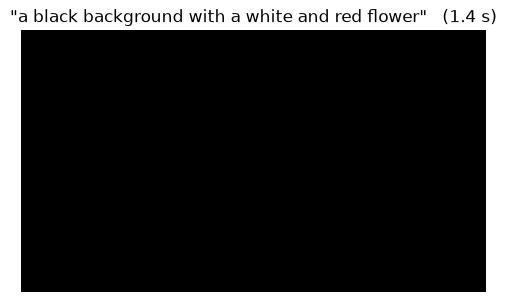

In [23]:
if not RUN_REAL_CAPTIONER:
    print("Skipped. Set RUN_REAL_CAPTIONER = True in the Part 2 settings to run this bonus.")
else:
    from transformers import BlipProcessor, BlipForConditionalGeneration

    blip_processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
    blip_model = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").eval()

    try:
        photo_bgr = take_photo()
    except RuntimeError:
        photo_bgr = None
    if photo_bgr is None:
        photo_bgr = sign_bgr
        print("Camera not available: the sample sign is used.")
    photo = Image.fromarray(cv2.cvtColor(photo_bgr, cv2.COLOR_BGR2RGB))

    t0 = time.perf_counter()
    with torch.no_grad():
        output_ids = blip_model.generate(**blip_processor(images=photo, return_tensors="pt"), max_new_tokens=30)
    seconds = time.perf_counter() - t0

    plt.figure(figsize=(6, 4.5))
    plt.imshow(photo)
    plt.axis("off")
    plt.title(f'"{blip_processor.decode(output_ids[0], skip_special_tokens=True)}"   ({seconds:.1f} s)', fontsize=12)
    plt.show()

# Part 3: Image retrieval with CLIP

**Image retrieval** finds the pictures of a collection that match a query, by **meaning** and not by file name.
A photo library can answer "a dog on the beach" even if no file is named like that. The query can be **text** or **another picture**.

## CLIP: words and pictures in the same space

**CLIP** (OpenAI, 2021) is made of two networks trained together on about 400 million (picture, caption) pairs from the internet:

- an **image encoder** that turns a picture into **512 numbers**
- a **text encoder** that turns a sentence into **512 numbers**

**Training idea.** In a batch of N pairs, CLIP computes an N x N grid of similarities between every picture and every caption.
The **diagonal** (the true pairs) is pushed **up**, and everything else is pushed **down**.
After training, a picture and a sentence that mean the same thing get **similar vectors**.

## The four steps of retrieval

| Step | Name | What happens |
|---|---|---|
| 1 | **Index** | Every picture of the collection is converted once into a vector |
| 2 | **Query** | The text (or the query picture) is converted into a vector with the same network |
| 3 | **Compare** | **Cosine similarity** between the query vector and every picture vector (1 = same direction = same meaning) |
| 4 | **Rank** | Pictures are sorted from the most to the least similar. The top K are shown |

**Collection used here.** 1,000 pictures from **CIFAR-10** (100 for each of 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck).
The class labels serve as the **ground truth** for the metrics. The pictures are only 32 x 32 pixels, so thumbnails look pixelated, but CLIP understands them.

| Setting | Meaning |
|---|---|
| `GALLERY_PER_CLASS` | Pictures per class in the collection |
| `QUERY_TEXT` | Free text typed by the user (any sentence works) |
| `QUERY_IMAGE_PATH` | Optional path of an own picture used as a query |
| `USE_WEBCAM_QUERY` | `True` = a webcam photo is used as the query picture |

In [24]:
GALLERY_PER_CLASS = 100
QUERY_TEXT        = "something that can fly"
QUERY_IMAGE_PATH  = None            # example: "my_picture.jpg"
USE_WEBCAM_QUERY  = False

from torchvision.datasets import CIFAR10
from transformers import CLIPModel, CLIPProcessor

# ---- The collection (and the labels used as ground truth)
cifar = CIFAR10(root="data", train=False, download=True)
class_names = cifar.classes
targets = np.array(cifar.targets)
by_class = [np.where(targets == c)[0] for c in range(10)]
gallery_idx = np.concatenate([idx[:GALLERY_PER_CLASS] for idx in by_class])                        # the collection
query_idx = np.concatenate([idx[GALLERY_PER_CLASS:GALLERY_PER_CLASS + 20] for idx in by_class])    # 20 other pictures per class, used as queries
gallery_labels, query_labels = targets[gallery_idx], targets[query_idx]


def as_picture(index):
    return Image.fromarray(cifar.data[index])


# ---- CLIP
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")


@torch.no_grad()
def embed_images(pictures, batch_size=64):
    """Step 1 and 2 for pictures: picture -> 512 numbers (normalized)."""
    vectors = []
    for i in range(0, len(pictures), batch_size):
        inputs = clip_processor(text=["a"], images=pictures[i:i + batch_size], return_tensors="pt", padding=True)
        vectors.append(F.normalize(clip_model(**inputs).image_embeds, dim=-1))
    return torch.cat(vectors)


blank_picture = Image.new("RGB", (224, 224))

@torch.no_grad()
def embed_texts(texts):
    """Step 2 for text: sentence -> 512 numbers (normalized)."""
    inputs = clip_processor(text=list(texts), images=[blank_picture], return_tensors="pt", padding=True, truncation=True)
    return F.normalize(clip_model(**inputs).text_embeds, dim=-1)


t0 = time.time()
gallery_vecs = embed_images([as_picture(i) for i in gallery_idx])
print(f"Indexed {len(gallery_vecs)} pictures in {time.time() - t0:.0f} s. Each picture is now {gallery_vecs.shape[1]} numbers.")

class_prompts = [f"a photo of a {name}" for name in class_names]
class_text_vecs = embed_texts(class_prompts)

100%|██████████| 170M/170M [51:40<00:00, 55.0kB/s]   
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 19454.51it/s]


Indexed 1000 pictures in 57 s. Each picture is now 512 numbers.


## Step 10: The embedding space

The 512 numbers of each picture cannot be drawn, but they can be **projected to 2 dimensions** (PCA) to get a map of the collection.
Pictures of the same class should form **neighborhoods**, and similar classes (cat and dog, automobile and truck) should be close.

The second figure is the **similarity grid** of CLIP's training idea, with real data:
one picture per class (rows) against the 10 sentences "a photo of a ..." (columns).
The bright **diagonal** shows that each picture is closest to its own sentence.

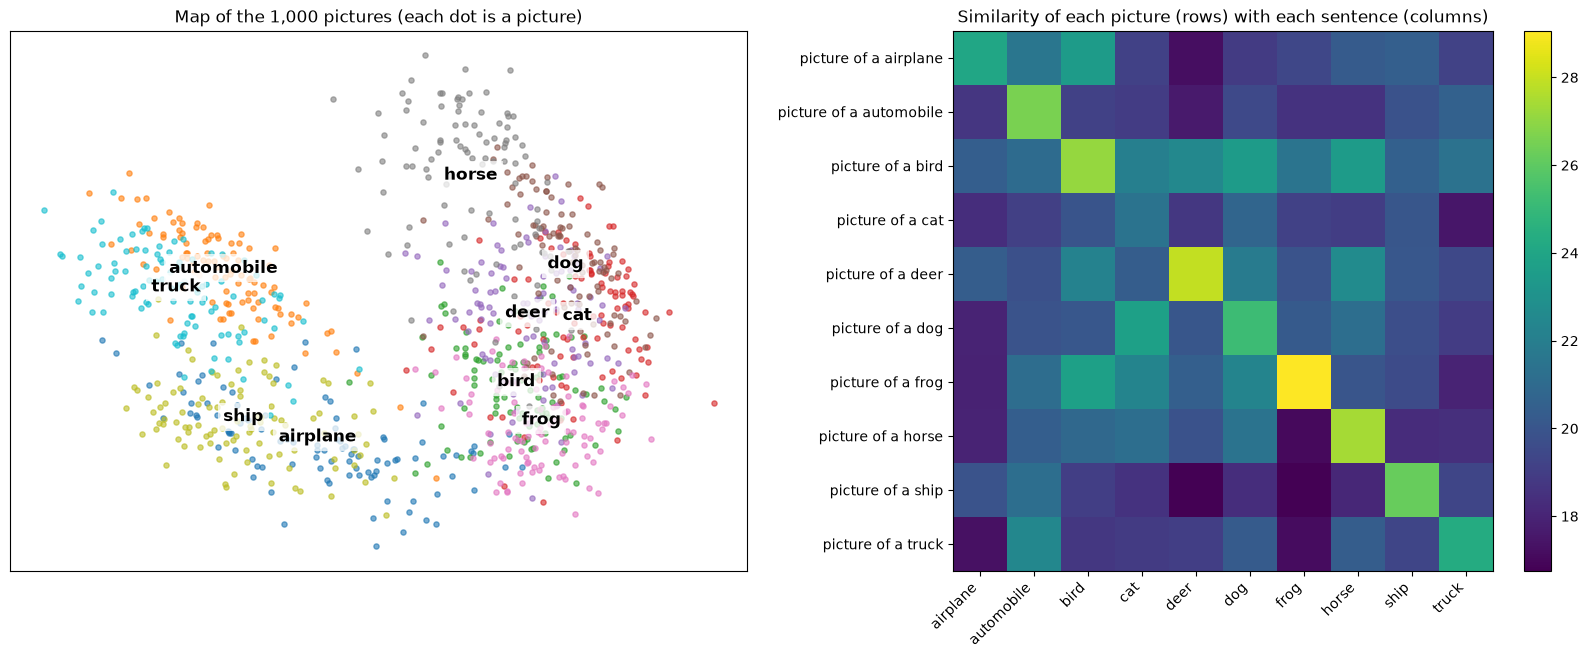

In [26]:
# ---- Map of the collection (PCA to 2 dimensions)
centered = gallery_vecs - gallery_vecs.mean(dim=0)
_, _, components = torch.linalg.svd(centered, full_matrices=False)
coords = (centered @ components[:2].T).numpy()

colors = plt.cm.tab10(np.arange(10))
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.2, 1]})

for c in range(10):
    mask = gallery_labels == c
    axes[0].scatter(coords[mask, 0], coords[mask, 1], s=14, color=colors[c], alpha=0.6)
    axes[0].text(coords[mask, 0].mean(), coords[mask, 1].mean(), class_names[c], fontsize=12, fontweight="bold",
                 ha="center", bbox=dict(facecolor="white", alpha=0.75, edgecolor="none"))
axes[0].set_title("Map of the 1,000 pictures (each dot is a picture)")
axes[0].set_xticks([])
axes[0].set_yticks([])

# ---- Similarity grid: one picture per class against the 10 sentences
one_per_class = [int(np.where(gallery_labels == c)[0][0]) for c in range(10)]
grid = (gallery_vecs[one_per_class] @ class_text_vecs.T).numpy() * 100
heat = axes[1].imshow(grid, cmap="viridis")
axes[1].set_xticks(range(10))
axes[1].set_xticklabels(class_names, rotation=45, ha="right")
axes[1].set_yticks(range(10))
axes[1].set_yticklabels([f"picture of a {n}" for n in class_names])
axes[1].set_title("Similarity of each picture (rows) with each sentence (columns)")
plt.colorbar(heat, ax=axes[1], fraction=0.046)
plt.tight_layout()
plt.show()

## Step 11: Searching

Two kinds of queries:

- **Text to image**: a sentence is converted to a vector and compared with all pictures. Sentences that name no class at all
  ("something that can fly", "a fast vehicle on the road") also work, because CLIP knows **meanings**.
- **Image to image**: a picture is converted to a vector and the most similar pictures of the collection are returned.

Under each result: its true class and its **similarity score**. In results with a known target, **green** marks a relevant picture.

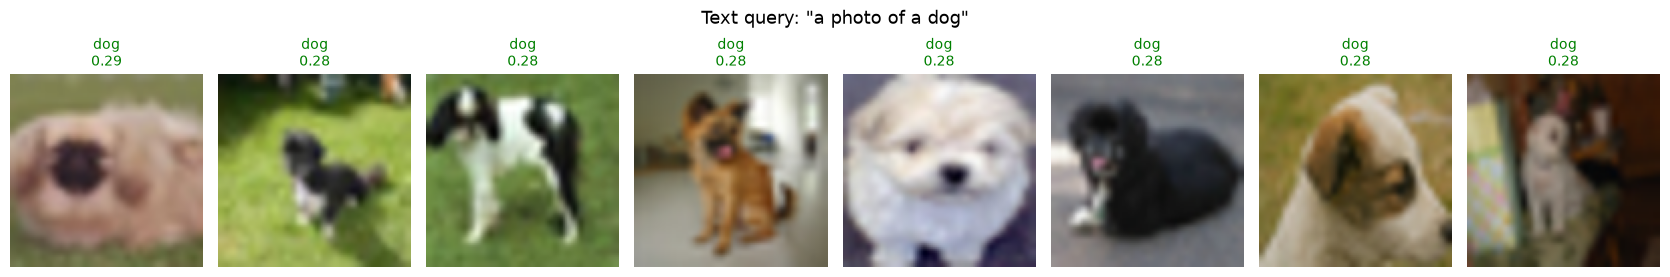

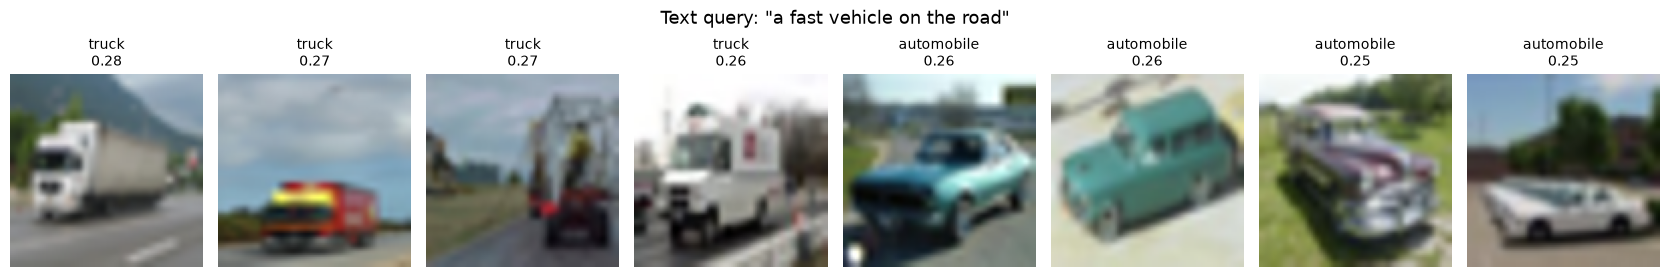

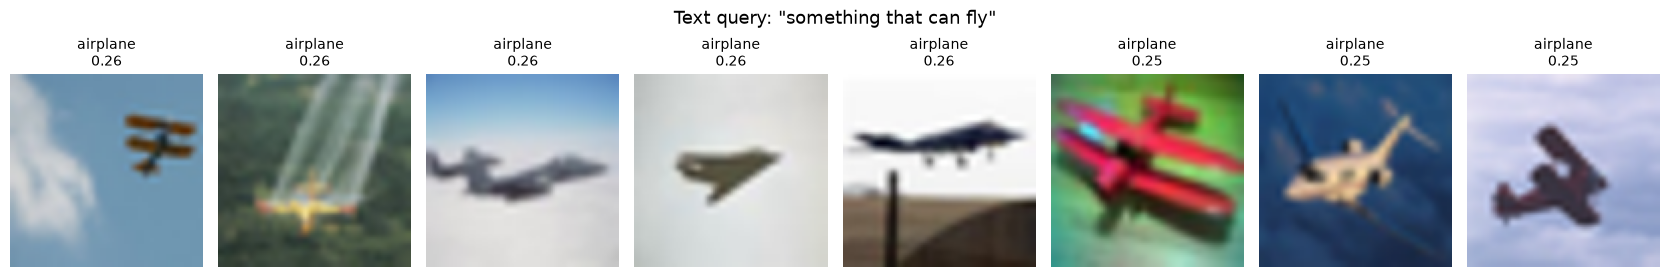

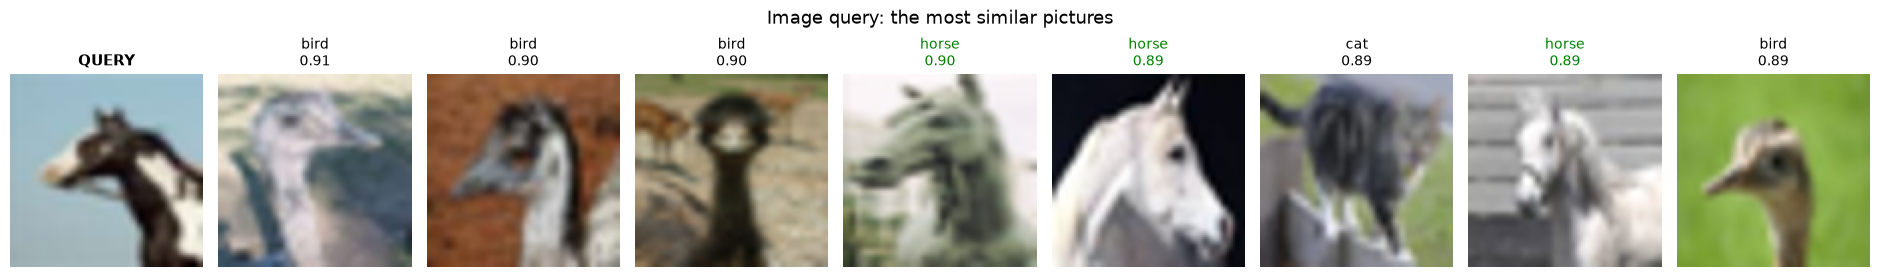

In [27]:
def show_results(title, indices, scores, query_picture=None, target_class=None):
    count = len(indices) + (1 if query_picture is not None else 0)
    fig, axes = plt.subplots(1, count, figsize=(2.1 * count, 3.0))
    axes = np.atleast_1d(axes)
    offset = 0
    if query_picture is not None:
        axes[0].imshow(query_picture.resize((96, 96), Image.BICUBIC))
        axes[0].set_title("QUERY", fontsize=11, fontweight="bold")
        axes[0].axis("off")
        offset = 1
    for ax, i, score in zip(axes[offset:], indices, scores):
        label = gallery_labels[i]
        ax.imshow(as_picture(gallery_idx[i]).resize((96, 96), Image.BICUBIC))
        ax.axis("off")
        ax.set_title(f"{class_names[label]}\n{score:.2f}", fontsize=10,
                     color="green" if target_class is not None and label == target_class else "black")
    fig.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


def search_text(query, k=8):
    similarity = (gallery_vecs @ embed_texts([query]).T).squeeze(1)
    top = similarity.topk(k)
    return top.indices.tolist(), top.values.tolist()


def search_image(picture, k=8):
    similarity = (gallery_vecs @ embed_images([picture]).T).squeeze(1)
    top = similarity.topk(k)
    return top.indices.tolist(), top.values.tolist()


# ---- Text to image
indices, scores = search_text("a photo of a dog")
show_results('Text query: "a photo of a dog"', indices, scores, target_class=class_names.index("dog"))

for text in ["a fast vehicle on the road", QUERY_TEXT]:
    indices, scores = search_text(text)
    show_results(f'Text query: "{text}"', indices, scores)

# ---- Image to image
if QUERY_IMAGE_PATH:
    query_picture, query_class = Image.open(QUERY_IMAGE_PATH).convert("RGB"), None
elif USE_WEBCAM_QUERY:
    shot = take_photo()
    query_picture, query_class = Image.fromarray(cv2.cvtColor(shot, cv2.COLOR_BGR2RGB)), None
else:
    horse_query = int(query_idx[class_names.index("horse") * 20])        # a horse picture that is NOT in the collection
    query_picture, query_class = as_picture(horse_query), class_names.index("horse")

indices, scores = search_image(query_picture)
show_results("Image query: the most similar pictures", indices, scores, query_picture=query_picture, target_class=query_class)

## Step 12: Retrieval metrics

For a query, every picture of the collection is **relevant** (same class as the query) or **not relevant**. The ranking is then scored:

| Metric | Question | Example | Better when |
|---|---|---|---|
| **Precision@K** | Among the K pictures shown, how many are relevant? | 9 relevant pictures in the top 10 -> **90%** | Higher |
| **Recall@K** | Among all the relevant pictures of the collection, how many are in the top K? | 80 of the 100 dogs are in the top 100 -> **80%** | Higher |
| **Average Precision (AP)** | Are the relevant pictures **near the top** of the whole list? Rewards a relevant picture at rank 1 more than at rank 50 | 100% = all relevant pictures come first | Higher |
| **mAP** (mean AP) | The average of AP over many queries: **one overall grade** | | Higher |
| **Zero-shot accuracy** | If the 10 sentences "a photo of a ..." act as classes, how often is the best sentence the right one? | | Higher |

**Baselines.** A number alone means little: it must be compared. Two baselines are measured for image queries:

- **Random**: pictures shown in a random order (mAP close to 10%, since 1 picture in 10 is relevant)
- **Raw pixels**: pictures compared by their pixel values (no understanding of meaning, only colors and layout)

CLIP should be far above both. The **confusion matrix** shows which classes are mistaken for which ones.

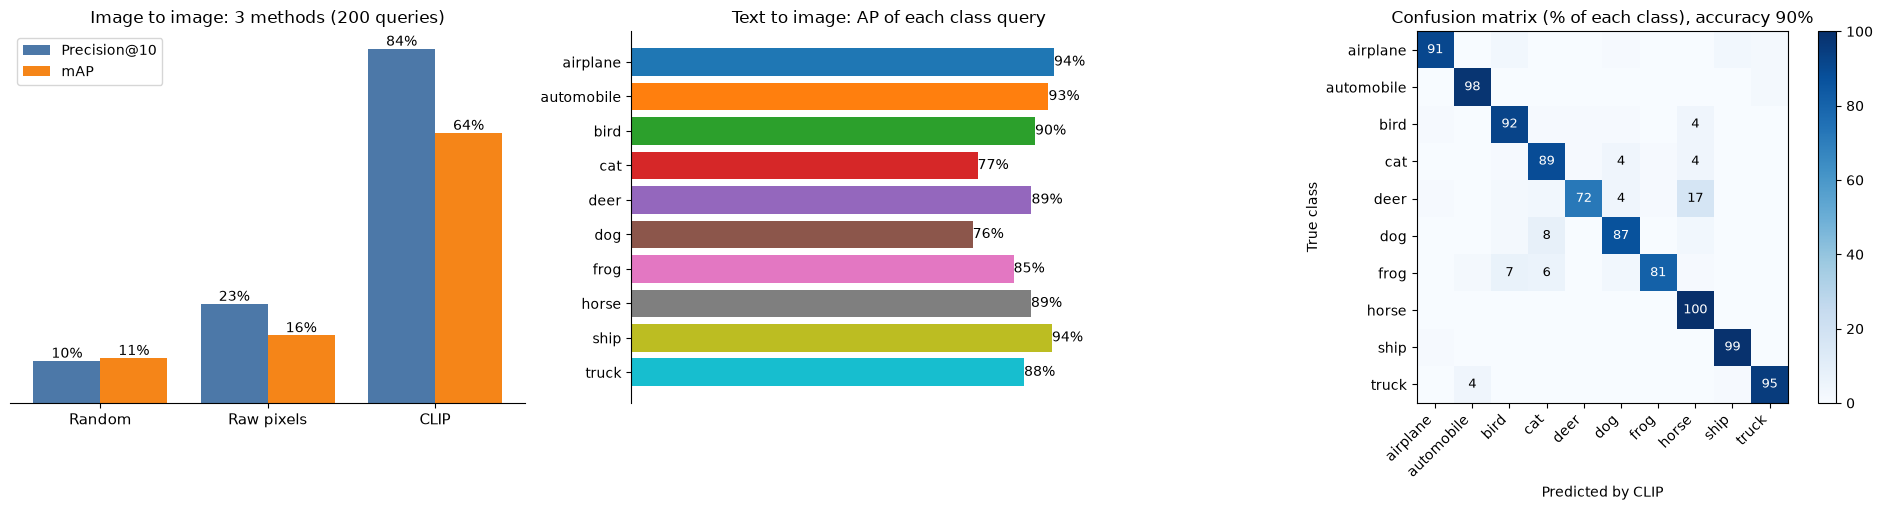

Image to image    Precision@10  Recall@100     mAP
Random                     10%         10%     11%
Raw pixels                 23%         17%     16%
CLIP                       84%         60%     64%

Text to image   : Precision@10 96%, Recall@100 82%, mAP 88%
Zero-shot accuracy with the 10 sentences: 90%


In [28]:
def average_precision(relevant):
    """relevant: 1/0 for every picture, in ranking order."""
    hits = np.cumsum(relevant)
    precision_at_each_rank = hits / (np.arange(len(relevant)) + 1)
    return float((precision_at_each_rank * relevant).sum() / max(relevant.sum(), 1))


def evaluate(similarity, q_labels, g_labels, precision_k=10, recall_k=GALLERY_PER_CLASS):
    """Returns Precision@K, Recall@K, and AP for every query."""
    p_at_k, r_at_k, ap = [], [], []
    for row, label in zip(similarity, q_labels):
        order = np.argsort(-row)
        relevant = (g_labels[order] == label).astype(np.float32)
        p_at_k.append(relevant[:precision_k].mean())
        r_at_k.append(relevant[:recall_k].sum() / relevant.sum())
        ap.append(average_precision(relevant))
    return np.array(p_at_k), np.array(r_at_k), np.array(ap)


# ---- Text to image: 10 queries ("a photo of a ...")
similarity_text = (class_text_vecs @ gallery_vecs.T).numpy()
p_text, r_text, ap_text = evaluate(similarity_text, np.arange(10), gallery_labels)

# ---- Image to image: 200 query pictures, three methods
query_vecs = embed_images([as_picture(i) for i in query_idx])
similarity_clip = (query_vecs @ gallery_vecs.T).numpy()
similarity_random = np.random.default_rng(0).random(similarity_clip.shape)

def pixel_vectors(indices):
    flat = cifar.data[indices].reshape(len(indices), -1).astype(np.float32)
    flat -= flat.mean(axis=1, keepdims=True)
    return flat / np.linalg.norm(flat, axis=1, keepdims=True)

similarity_pixels = pixel_vectors(query_idx) @ pixel_vectors(gallery_idx).T

methods = {"Random": similarity_random, "Raw pixels": similarity_pixels, "CLIP": similarity_clip}
scores_by_method = {name: evaluate(sim, query_labels, gallery_labels) for name, sim in methods.items()}

# ---- Zero-shot classification and confusion matrix
predicted = (gallery_vecs @ class_text_vecs.T).argmax(dim=1).numpy()
accuracy = float((predicted == gallery_labels).mean())
confusion = np.zeros((10, 10))
for true, guess in zip(gallery_labels, predicted):
    confusion[true, guess] += 1
confusion /= confusion.sum(axis=1, keepdims=True)

# ---- Figures
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2), gridspec_kw={"width_ratios": [1, 1, 1.15]})

x = np.arange(3)
p_values = [scores_by_method[m][0].mean() * 100 for m in methods]
map_values = [scores_by_method[m][2].mean() * 100 for m in methods]
bars1 = axes[0].bar(x - 0.2, p_values, 0.4, label="Precision@10", color="#4C78A8")
bars2 = axes[0].bar(x + 0.2, map_values, 0.4, label="mAP", color="#F58518")
axes[0].bar_label(bars1, fmt="%.0f%%")
axes[0].bar_label(bars2, fmt="%.0f%%")
axes[0].set_xticks(x)
axes[0].set_xticklabels(list(methods), fontsize=11)
axes[0].set_yticks([])
axes[0].set_title("Image to image: 3 methods (200 queries)")
axes[0].legend()
axes[0].spines[["top", "right", "left"]].set_visible(False)

bars = axes[1].barh(class_names[::-1], ap_text[::-1] * 100, color=colors[::-1])
axes[1].bar_label(bars, fmt="%.0f%%")
axes[1].set_xlim(0, 115)
axes[1].set_xticks([])
axes[1].set_title("Text to image: AP of each class query")
axes[1].spines[["top", "right", "bottom"]].set_visible(False)

shown = axes[2].imshow(confusion * 100, cmap="Blues", vmin=0, vmax=100)
for i in range(10):
    for j in range(10):
        if confusion[i, j] >= 0.04:
            axes[2].text(j, i, f"{confusion[i, j] * 100:.0f}", ha="center", va="center",
                         color="white" if confusion[i, j] > 0.5 else "black", fontsize=9)
axes[2].set_xticks(range(10))
axes[2].set_xticklabels(class_names, rotation=45, ha="right")
axes[2].set_yticks(range(10))
axes[2].set_yticklabels(class_names)
axes[2].set_xlabel("Predicted by CLIP")
axes[2].set_ylabel("True class")
axes[2].set_title(f"Confusion matrix (% of each class), accuracy {accuracy:.0%}")
plt.colorbar(shown, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

print(f"{'Image to image':<16}{'Precision@10':>14}{'Recall@100':>12}{'mAP':>8}")
for name, (p, r, ap) in scores_by_method.items():
    print(f"{name:<16}{p.mean():>14.0%}{r.mean():>12.0%}{ap.mean():>8.0%}")
print(f"\nText to image   : Precision@10 {p_text.mean():.0%}, Recall@100 {r_text.mean():.0%}, mAP {ap_text.mean():.0%}")
print(f"Zero-shot accuracy with the 10 sentences: {accuracy:.0%}")

# Recap

| | **OCR** | **Image captioning** | **Image retrieval** |
|---|---|---|---|
| **Input -> output** | Picture -> text | Picture -> sentence | Text or picture -> ranked pictures |
| **Architecture** | Detection network, then CNN + LSTM + CTC | CNN encoder + LSTM decoder | Image encoder + text encoder (CLIP), then nearest neighbors |
| **How the output is produced** | One letter for every slice of a text line | One word at a time, starting after `<start>`, until `<end>` | Cosine similarity, then sorting |
| **Main metrics** | CER, WER | BLEU, CIDEr, attribute accuracy | Precision@K, Recall@K, mAP |
| **Metrics in plain words** | How much of the text is wrong? | How close is the sentence to what humans write? | Are the right pictures at the top? |
| **Needs a ground truth?** | Yes for CER and WER. Not for speed and confidence | Yes | Yes (labels) |

**Key ideas**

- A picture is always converted into **numbers** first. What differs is what the numbers are turned into.
- **CNN + LSTM** appears in two places: reading a line of text (OCR) and writing a sentence (captioning).
- A **confidence** or similarity score is the model's own feeling. Only a comparison with a **ground truth** measures correctness.
- A metric needs a **baseline** (random, raw pixels) to have a meaning.
- A sentence or a ranking has several valid answers, so metrics compare **overlap** or **order**, not a single answer.

## Troubleshooting

| Problem | Solution |
|---|---|
| "Cannot open the camera" | Allow camera access for VS Code, close Zoom/Teams/Meet, try `CAMERA_INDEX = 1` |
| `rapidocr-onnxruntime` does not install | Use `pip install easyocr` and set `OCR_ENGINE = "easyocr"` |
| OCR reads nothing or wrong text | More light, larger text, hold the page flat and steady, lower `MIN_CONFIDENCE` |
| OCR video is slow | Increase `OCR_EVERY_N_FRAMES` or lower `OCR_WIDTH` |
| The captioning model makes many errors | Increase `EPOCHS` (for example 50) and set `FORCE_RETRAIN = True` |
| Training is slow | Lower `TRAIN_IMAGES` to 1000 |
| CIFAR-10 download fails | Check the internet connection, then run the cell again |
| Error about `nltk` | `pip install nltk` |

## Limits and responsible use

- **OCR** can read private information (ID cards, license plates, medical documents). Reading someone else's documents needs permission.
- **Captioning and retrieval models** reflect the **biases** of the data they were trained on, and may describe or rank people unfairly.
- **Retrieval by face or by person** can be used for surveillance. It should be used with consent and a clear purpose.